# 02 · Calidad de Datos — Churn Bancario

Análisis de calidad del dataset `competencia_01.csv`.  
Cubre: duplicados, integridad del panel, data drift, consistencia entre variables y missings estructurales.

**Contexto del dataset (EDA previo):**
- 983.061 filas × 155 columnas
- 6 meses: `202103` → `202108` (~163-165k clientes/mes)
- Target `clase_ternaria`: `continua`, `baja1`, `baja2`, `sin_target`
- 46 columnas con ≥1% de nulos; bloques Visa/Master con ~59% de nulos

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 2 — Calidad de datos  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

RUTA_CARPETA = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
ARCHIVO_DATOS = RUTA_CARPETA / 'competencia_01.csv'

# Constantes del dataset (confirmadas en EDA 01)
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET      = 'clase_ternaria'
MESES_ESPERADOS = [202103, 202104, 202105, 202106, 202107, 202108]
MES_SIN_TARGET  = 202108   # este mes no tiene label real

print(f'Archivo encontrado: {ARCHIVO_DATOS.exists()}')

Archivo encontrado: True


## 1 · Carga optimizada

Reutilizamos la misma lógica de dtype inference del notebook 01.

In [3]:
def inferir_dtypes_optimos(df_muestra: pd.DataFrame, umbral_categorica: float = 0.05) -> dict:
    dtypes = {}
    for col in df_muestra.columns:
        tipo = df_muestra[col].dtype
        if tipo == 'float64':
            dtypes[col] = 'float32'
        elif tipo == 'int64':
            col_min = df_muestra[col].min()
            col_max = df_muestra[col].max()
            if col_min >= 0:
                if col_max < 256:     dtypes[col] = 'uint8'
                elif col_max < 65536: dtypes[col] = 'uint16'
                else:                 dtypes[col] = 'uint32'
            else:
                if col_min > -128 and col_max < 128:       dtypes[col] = 'int8'
                elif col_min > -32768 and col_max < 32768: dtypes[col] = 'int16'
                else:                                      dtypes[col] = 'int32'
        elif tipo == 'object':
            if df_muestra[col].nunique() / len(df_muestra) < umbral_categorica:
                dtypes[col] = 'category'
    return dtypes

muestra = pd.read_csv(ARCHIVO_DATOS, nrows=500)
dtypes_optimos = inferir_dtypes_optimos(muestra)
del muestra; gc.collect()

df = pd.read_csv(ARCHIVO_DATOS, dtype=dtypes_optimos, low_memory=False)
mem_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f'Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem_mb:.1f} MB')

Dataset cargado: 983,061 filas × 155 columnas — 404.1 MB


---
## 2 · Duplicados

En un panel longitudinal la clave natural es `(numero_de_cliente, foto_mes)`.  
Chequeamos tres niveles: filas 100% duplicadas, duplicados por clave compuesta, y clientes que aparecen más de una vez dentro de un mismo mes.

In [4]:
# 2.1 Filas completamente duplicadas
n_dup_totales = df.duplicated().sum()
print(f'Filas 100% duplicadas: {n_dup_totales:,} ({n_dup_totales/len(df)*100:.3f}%)')

# 2.2 Duplicados por clave compuesta (cliente + mes)
n_dup_clave = df.duplicated(subset=[COL_ID, COL_PERIODO]).sum()
print(f'Duplicados por (cliente, mes): {n_dup_clave:,} ({n_dup_clave/len(df)*100:.3f}%)')

if n_dup_clave > 0:
    print('\nEjemplos de claves duplicadas:')
    claves_dup = (
        df[df.duplicated(subset=[COL_ID, COL_PERIODO], keep=False)]
        .groupby([COL_ID, COL_PERIODO]).size().reset_index(name='n_apariciones')
        .sort_values('n_apariciones', ascending=False)
        .head(10)
    )
    print(claves_dup)

Filas 100% duplicadas: 0 (0.000%)
Duplicados por (cliente, mes): 0 (0.000%)


Distribución de meses por cliente:
         n_clientes    pct
n_meses                   
1              2425   1.43
2              2061   1.21
3              2611   1.54
4              2306   1.36
5              2487   1.47
6            157837  92.99


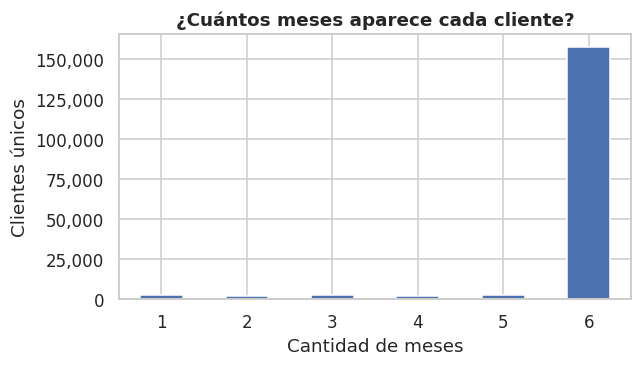

15

In [5]:
# 2.3 Distribución de apariciones por cliente
# Cuántos meses aparece cada cliente: esperado = 1 a 6
apariciones = df.groupby(COL_ID)[COL_PERIODO].count().rename('n_meses')
dist_apariciones = apariciones.value_counts().sort_index()

print('Distribución de meses por cliente:')
print(dist_apariciones.to_frame('n_clientes').assign(
    pct=lambda x: (x['n_clientes'] / x['n_clientes'].sum() * 100).round(2)
))

fig, ax = plt.subplots(figsize=(6, 3.5))
dist_apariciones.plot(kind='bar', ax=ax, color='#4C72B0', edgecolor='white')
ax.set_title('¿Cuántos meses aparece cada cliente?', fontsize=12, fontweight='bold')
ax.set_xlabel('Cantidad de meses')
ax.set_ylabel('Clientes únicos')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

del apariciones; gc.collect()

---
## 3 · Integridad del panel

Verificamos si el panel es **balanceado** (todo cliente aparece en todos los meses)  
y detectamos clientes con **entradas o salidas abruptas** — relevante para el modelo  
porque un cliente que desaparece antes de `202108` podría ya haber hecho churn.

In [6]:
# 3.1 Clientes únicos por mes
clientes_por_mes = df.groupby(COL_PERIODO)[COL_ID].nunique()
print('Clientes únicos por mes:')
print(clientes_por_mes.to_frame())

total_clientes = df[COL_ID].nunique()
print(f'\nTotal de clientes únicos en todo el dataset: {total_clientes:,}')

Clientes únicos por mes:
          numero_de_cliente
foto_mes                   
202103               162900
202104               163284
202105               163768
202106               164114
202107               164348
202108               164647

Total de clientes únicos en todo el dataset: 169,727


In [7]:
# 3.2 Clientes que NO están en todos los meses (panel desbalanceado)
# Usamos una tabla pivot de presencia: cliente x mes -> 1/0
presencia = (
    df[[COL_ID, COL_PERIODO]]
    .assign(presente=1)
    .pivot_table(index=COL_ID, columns=COL_PERIODO, values='presente', fill_value=0)
)

n_meses_totales = len(MESES_ESPERADOS)
presencia['total_meses'] = presencia.sum(axis=1)

resumen_presencia = presencia['total_meses'].value_counts().sort_index()
clientes_panel_completo = (presencia['total_meses'] == n_meses_totales).sum()

print(f'Clientes en los {n_meses_totales} meses completos: {clientes_panel_completo:,} ({clientes_panel_completo/total_clientes*100:.1f}%)')
print(f'Clientes con meses faltantes: {total_clientes - clientes_panel_completo:,}')

Clientes en los 6 meses completos: 157,837 (93.0%)
Clientes con meses faltantes: 11,890


In [8]:
# 3.3 Patrones de entrada/salida del panel
# Para cada cliente: primer mes y último mes en el dataset
primer_mes = df.groupby(COL_ID)[COL_PERIODO].min().rename('primer_mes')
ultimo_mes = df.groupby(COL_ID)[COL_PERIODO].max().rename('ultimo_mes')
panel_info = pd.concat([primer_mes, ultimo_mes], axis=1)

# Clientes que desaparecen antes del último mes (posible churn ya ocurrido)
desaparecen = panel_info[panel_info['ultimo_mes'] < MESES_ESPERADOS[-1]]
print(f'Clientes que desaparecen antes de {MESES_ESPERADOS[-1]}: {len(desaparecen):,}')
print('\nDistribución de último mes para clientes que salen antes:')
print(desaparecen['ultimo_mes'].value_counts().sort_index())

# Clientes que ingresan después del primer mes
ingresan_tarde = panel_info[panel_info['primer_mes'] > MESES_ESPERADOS[0]]
print(f'\nClientes que ingresan después de {MESES_ESPERADOS[0]}: {len(ingresan_tarde):,}')
print('Distribución de primer mes para clientes nuevos:')
print(ingresan_tarde['primer_mes'].value_counts().sort_index())

del primer_mes, ultimo_mes, panel_info, desaparecen, ingresan_tarde, presencia
gc.collect()

Clientes que desaparecen antes de 202108: 5,080

Distribución de último mes para clientes que salen antes:
ultimo_mes
202103    1013
202104     955
202105    1138
202106     871
202107    1103
Name: count, dtype: int64

Clientes que ingresan después de 202103: 6,827
Distribución de primer mes para clientes nuevos:
primer_mes
202104    1403
202105    1447
202106    1480
202107    1102
202108    1395
Name: count, dtype: int64


0

---
## 4 · Data Drift entre meses

Medimos si las distribuciones de las variables cambian significativamente de un mes a otro.  
Usamos el **test KS (Kolmogorov-Smirnov)** para numéricas: compara mes base (202103) contra cada mes posterior.  
Un p-value bajo y un estadístico D alto indican drift real en esa variable.

In [9]:
# Variables numéricas a analizar (excluimos IDs, período y target)
EXCLUIR_DRIFT = {COL_ID, COL_PERIODO, TARGET}
cols_numericas = [
    c for c in df.select_dtypes(include=[np.number]).columns
    if c not in EXCLUIR_DRIFT
]

mes_base = MESES_ESPERADOS[0]
meses_comparar = MESES_ESPERADOS[1:]

df_base = df[df[COL_PERIODO] == mes_base]

resultados_drift = []

for mes in meses_comparar:
    df_mes = df[df[COL_PERIODO] == mes]
    for col in cols_numericas:
        a = df_base[col].dropna().values
        b = df_mes[col].dropna().values
        if len(a) < 30 or len(b) < 30:
            continue
        ks_stat, ks_pval = stats.ks_2samp(a, b)
        resultados_drift.append({
            'mes': mes,
            'variable': col,
            'ks_stat': round(ks_stat, 4),
            'ks_pval': round(ks_pval, 6)
        })
    del df_mes

del df_base
gc.collect()

drift_df = pd.DataFrame(resultados_drift)
# Clasificamos nivel de drift
drift_df['drift'] = pd.cut(
    drift_df['ks_stat'],
    bins=[0, 0.05, 0.10, 0.20, 1.0],
    labels=['bajo', 'moderado', 'alto', 'crítico']
)

print(f'Combinaciones (mes × variable) analizadas: {len(drift_df):,}')
print('\nResumen por nivel de drift:')
print(drift_df['drift'].value_counts())

Combinaciones (mes × variable) analizadas: 760

Resumen por nivel de drift:
drift
bajo        649
moderado     63
crítico      20
alto         11
Name: count, dtype: int64


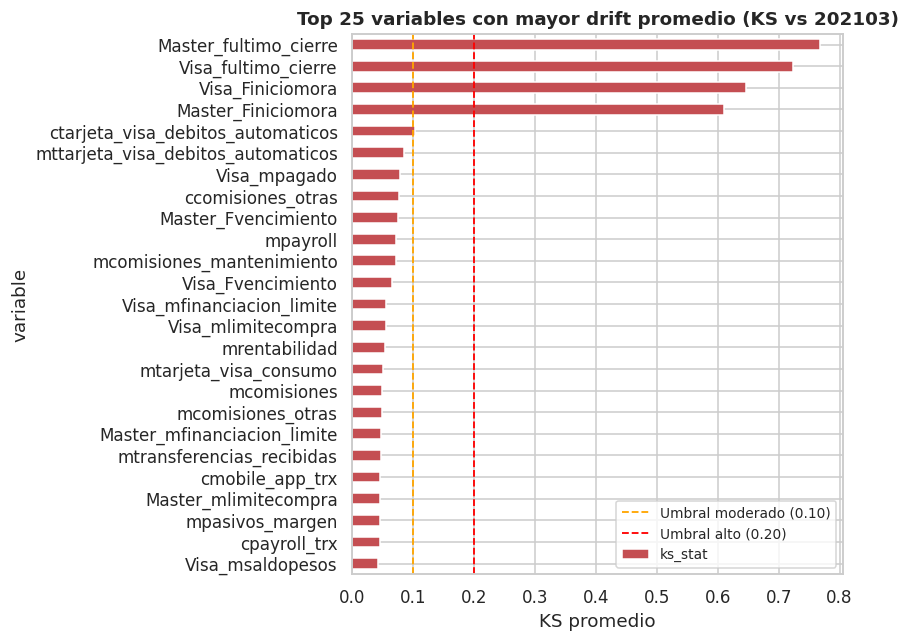

In [10]:
# Top variables con mayor drift promedio vs mes base
drift_promedio = (
    drift_df.groupby('variable')['ks_stat']
    .mean()
    .sort_values(ascending=False)
    .head(25)
)

fig, ax = plt.subplots(figsize=(8, 6))
drift_promedio.sort_values().plot(kind='barh', ax=ax, color='#C44E52', edgecolor='white')
ax.axvline(0.10, color='orange', linestyle='--', linewidth=1.2, label='Umbral moderado (0.10)')
ax.axvline(0.20, color='red', linestyle='--', linewidth=1.2, label='Umbral alto (0.20)')
ax.set_title('Top 25 variables con mayor drift promedio (KS vs 202103)', fontsize=12, fontweight='bold')
ax.set_xlabel('KS promedio')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

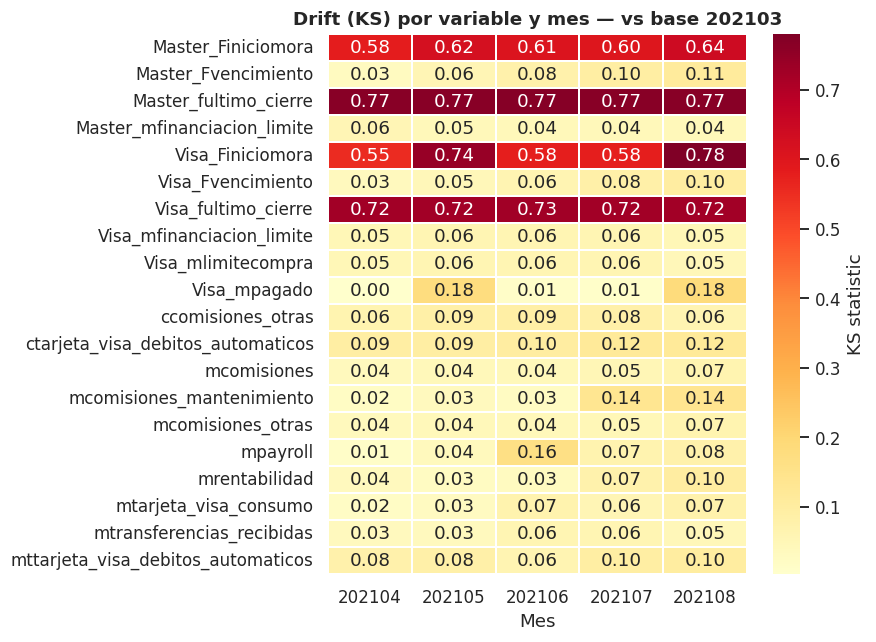

3257

In [11]:
# Heatmap: drift (KS) por mes y top-20 variables con más drift
top_vars_drift = drift_promedio.head(20).index.tolist()
heatmap_data = (
    drift_df[drift_df['variable'].isin(top_vars_drift)]
    .pivot(index='variable', columns='mes', values='ks_stat')
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap='YlOrRd',
    annot=True,
    fmt='.2f',
    linewidths=0.3,
    cbar_kws={'label': 'KS statistic'}
)
ax.set_title('Drift (KS) por variable y mes — vs base 202103', fontsize=12, fontweight='bold')
ax.set_xlabel('Mes')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

del drift_df, heatmap_data
gc.collect()

---
## 5 · Missings estructurales

Ya sabemos que el bloque Visa/Master tiene ~59% de nulos. La pregunta clave es:  
¿los nulos son **MCAR** (al azar) o **MAR/MNAR** (estructurales — el cliente simplemente no tiene tarjeta)?  
Si son estructurales, un flag binario `tiene_tarjeta` puede ser más informativo que imputar.

In [12]:
# 5.1 Tasa de nulos por bloque de variables
def bloque(col):
    if col.startswith('Master_'): return 'Master'
    if col.startswith('Visa_'):   return 'Visa'
    if col in ('ctarjeta_visa', 'ctarjeta_visa_transacciones', 'mtarjeta_visa_consumo',
                'ctarjeta_visa_descuentos', 'mtarjeta_visa_descuentos',
                'ctarjeta_visa_debitos_automaticos', 'mttarjeta_visa_debitos_automaticos'):
        return 'Visa (conteos)'
    if col in ('ctarjeta_master', 'ctarjeta_master_transacciones', 'mtarjeta_master_consumo',
                'ctarjeta_master_descuentos', 'mtarjeta_master_descuentos',
                'ctarjeta_master_debitos_automaticos', 'mttarjeta_master_debitos_automaticos'):
        return 'Master (conteos)'
    if col.startswith('c') or col.startswith('m'):
        if 'prestamo' in col: return 'Préstamos'
        if 'seguro' in col:   return 'Seguros'
        if 'plazo_fijo' in col or 'inversion' in col: return 'Inversiones'
        return 'Cuentas / Canales'
    return 'Perfil cliente'

nulos_por_col = df.isna().mean().mul(100)
bloques = pd.DataFrame({'pct_nulos': nulos_por_col, 'bloque': [bloque(c) for c in df.columns]})
resumen_bloques = bloques.groupby('bloque')['pct_nulos'].agg(['mean', 'max', 'min']).round(2)
resumen_bloques.columns = ['pct_nulos_promedio', 'pct_nulos_max', 'pct_nulos_min']
print('Nulos promedio por bloque de variables:')
print(resumen_bloques.sort_values('pct_nulos_promedio', ascending=False))

Nulos promedio por bloque de variables:
                   pct_nulos_promedio  pct_nulos_max  pct_nulos_min
bloque                                                             
Master                          34.17          99.51          10.14
Visa                            12.42          98.64           4.80
Master (conteos)                 0.42           2.97           0.00
Visa (conteos)                   0.30           2.11           0.00
Cuentas / Canales                0.00           0.00           0.00
Perfil cliente                   0.00           0.00           0.00
Inversiones                      0.00           0.00           0.00
Seguros                          0.00           0.00           0.00
Préstamos                        0.00           0.00           0.00


In [13]:
# 5.2 ¿Los nulos en Visa/Master son estructurales?
# Hipótesis: un cliente sin tarjeta Visa tiene NaN en TODAS las columnas Visa_
cols_master = [c for c in df.columns if c.startswith('Master_')]
cols_visa   = [c for c in df.columns if c.startswith('Visa_')]

# ¿Son los nulos consistentes dentro de cada cliente-mes?
nulos_master_por_fila = df[cols_master].isna().sum(axis=1)
nulos_visa_por_fila   = df[cols_visa].isna().sum(axis=1)

# Clasificamos cada fila
df['_tiene_master'] = (nulos_master_por_fila == 0).astype('int8')
df['_tiene_visa']   = (nulos_visa_por_fila == 0).astype('int8')

# Filas con nulos parciales (ni 0 ni todos) = inconsistencia
master_parcial = ((nulos_master_por_fila > 0) & (nulos_master_por_fila < len(cols_master))).sum()
visa_parcial   = ((nulos_visa_por_fila > 0)   & (nulos_visa_por_fila < len(cols_visa))).sum()

print(f'Filas con tarjeta Master completa (sin nulos): {df["_tiene_master"].sum():,}')
print(f'Filas con nulos PARCIALES en Master (inconsistencia): {master_parcial:,}')
print(f'\nFilas con tarjeta Visa completa (sin nulos): {df["_tiene_visa"].sum():,}')
print(f'Filas con nulos PARCIALES en Visa (inconsistencia): {visa_parcial:,}')

del nulos_master_por_fila, nulos_visa_por_fila; gc.collect()

Filas con tarjeta Master completa (sin nulos): 4,815
Filas con nulos PARCIALES en Master (inconsistencia): 878,602

Filas con tarjeta Visa completa (sin nulos): 13,310
Filas con nulos PARCIALES en Visa (inconsistencia): 922,565


0

Tasa de tenencia de tarjeta por mes:
          % con Master  % con Visa
foto_mes                          
202103            0.69        0.91
202104            0.60        0.87
202105            0.50        2.65
202106            0.40        0.57
202107            0.42        0.60
202108            0.34        2.53


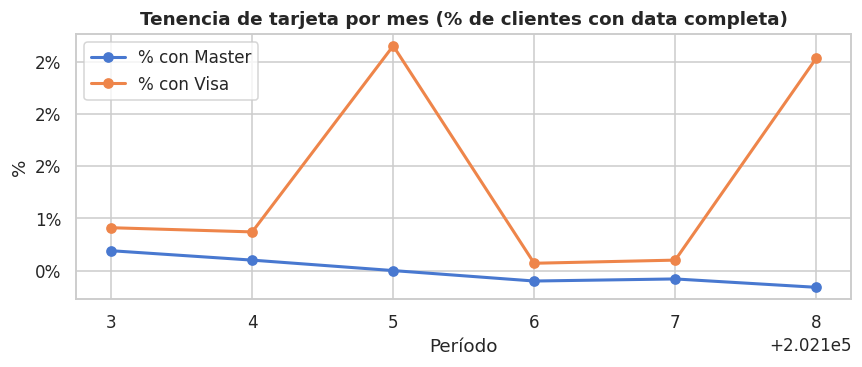


% nulos promedio por mes (todas las columnas):
foto_mes
202103    6.660
202104    6.653
202105    6.606
202106    6.538
202107    6.402
202108    6.506
Name: pct_nulos_promedio, dtype: float64


In [14]:
# 5.3 Tasa de tenencia de tarjeta por mes
tenencia_por_mes = df.groupby(COL_PERIODO)[['_tiene_master', '_tiene_visa']].mean().mul(100).round(2)
tenencia_por_mes.columns = ['% con Master', '% con Visa']
print('Tasa de tenencia de tarjeta por mes:')
print(tenencia_por_mes)

fig, ax = plt.subplots(figsize=(8, 3.5))
tenencia_por_mes.plot(ax=ax, marker='o', linewidth=2)
ax.set_title('Tenencia de tarjeta por mes (% de clientes con data completa)', fontsize=12, fontweight='bold')
ax.set_ylabel('%')
ax.set_xlabel('Período')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
plt.tight_layout()
plt.show()

# 5.4 Tasa de nulos por mes (¿crece o decrece?)
pct_nulos_por_mes = (
    df.groupby(COL_PERIODO)
    .apply(lambda g: g.isna().mean().mean() * 100)
    .rename('pct_nulos_promedio')
)
print('\n% nulos promedio por mes (todas las columnas):')
print(pct_nulos_por_mes.round(3))

In [15]:
# Limpiamos las columnas auxiliares antes de seguir
df.drop(columns=['_tiene_master', '_tiene_visa'], inplace=True)
gc.collect()

11975

---
## 6 · Consistencia entre variables relacionadas

Verificamos reglas de negocio que deberían cumplirse:  
si una variable de cantidad (conteo) es 0, el monto correspondiente debería ser 0 también y viceversa.  
Inconsistencias aquí pueden indicar errores de carga o valores imputados incorrectamente.

In [16]:
# Pares (conteo, monto) a verificar
pares_consistencia = [
    ('ctarjeta_visa_transacciones',    'mtarjeta_visa_consumo'),
    ('ctarjeta_master_transacciones',  'mtarjeta_master_consumo'),
    ('cprestamos_personales',          'mprestamos_personales'),
    ('cprestamos_prendarios',          'mprestamos_prendarios'),
    ('cprestamos_hipotecarios',        'mprestamos_hipotecarios'),
    ('cplazo_fijo',                    'mplazo_fijo_pesos'),
    ('cpayroll_trx',                   'mpayroll'),
    ('ctransferencias_recibidas',      'mtransferencias_recibidas'),
    ('ctransferencias_emitidas',       'mtransferencias_emitidas'),
    ('cextraccion_autoservicio',       'mextraccion_autoservicio'),
    ('ccheques_emitidos',              'mcheques_emitidos'),
    ('ccheques_depositados',           'mcheques_depositados'),
]

resultados_consistencia = []
for col_c, col_m in pares_consistencia:
    if col_c not in df.columns or col_m not in df.columns:
        continue
    sub = df[[col_c, col_m]].dropna()
    # Inconsistencia tipo A: cantidad > 0 pero monto == 0
    inc_a = ((sub[col_c] > 0) & (sub[col_m] == 0)).sum()
    # Inconsistencia tipo B: cantidad == 0 pero monto != 0
    inc_b = ((sub[col_c] == 0) & (sub[col_m] != 0)).sum()
    resultados_consistencia.append({
        'conteo': col_c,
        'monto': col_m,
        'n_filas': len(sub),
        'inc_cant>0_monto=0': inc_a,
        'inc_cant=0_monto≠0': inc_b,
        'pct_inconsistente': round((inc_a + inc_b) / len(sub) * 100, 3) if len(sub) > 0 else 0
    })

cons_df = pd.DataFrame(resultados_consistencia)
print('Verificación de consistencia cantidad-monto:')
print(cons_df.sort_values('pct_inconsistente', ascending=False).to_string(index=False))

Verificación de consistencia cantidad-monto:
                       conteo                     monto  n_filas  inc_cant>0_monto=0  inc_cant=0_monto≠0  pct_inconsistente
                  cplazo_fijo         mplazo_fijo_pesos   983061              122860                   0             12.498
                 cpayroll_trx                  mpayroll   983061                5757                  20              0.588
        cprestamos_prendarios     mprestamos_prendarios   983061                 257                  26              0.029
  ctarjeta_visa_transacciones     mtarjeta_visa_consumo   983061                   0                   1              0.000
        cprestamos_personales     mprestamos_personales   983061                   0                   1              0.000
ctarjeta_master_transacciones   mtarjeta_master_consumo   983061                   0                   1              0.000
      cprestamos_hipotecarios   mprestamos_hipotecarios   983061                   0   

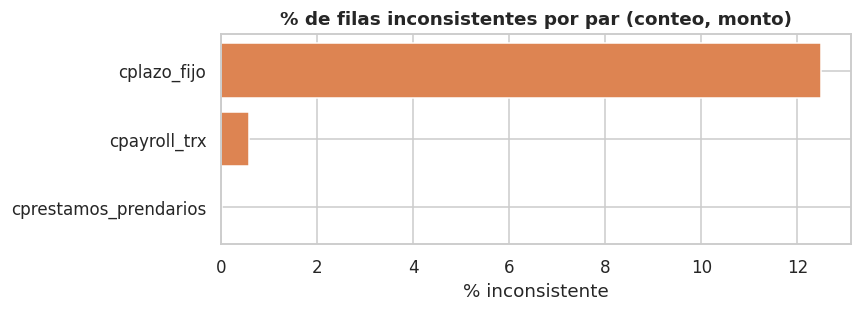

3301

In [17]:
# Visualización de pares con mayor inconsistencia
cons_plot = cons_df[cons_df['pct_inconsistente'] > 0].sort_values('pct_inconsistente', ascending=False)

if len(cons_plot) > 0:
    fig, ax = plt.subplots(figsize=(8, max(3, len(cons_plot) * 0.5)))
    ax.barh(cons_plot['conteo'], cons_plot['pct_inconsistente'], color='#DD8452', edgecolor='white')
    ax.set_title('% de filas inconsistentes por par (conteo, monto)', fontsize=12, fontweight='bold')
    ax.set_xlabel('% inconsistente')
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print('✓ Sin inconsistencias cantidad-monto detectadas.')

del cons_df, cons_plot; gc.collect()

---
## 7 · Outliers extremos por variable

Identificamos valores que superan **50 veces la desviación estándar** del mes (muy conservador —  
en datos bancarios hay distribuciones muy asimétricas, no queremos cortar legítimos).  
El objetivo es detectar errores de carga, no imputar.

In [18]:
EXCLUIR_OUTLIER = {COL_ID, COL_PERIODO, TARGET}
cols_float = [
    c for c in df.select_dtypes(include=['float32', 'float64']).columns
    if c not in EXCLUIR_OUTLIER
]

# Calculamos z-score robusto (mediana + MAD) sobre el dataset completo
# Hacemos chunk por columna para no explotar RAM
outliers_extremos = []
UMBRAL_Z = 50

for col in cols_float:
    serie = df[col].dropna()
    if len(serie) < 100:
        continue
    mediana = serie.median()
    mad     = (serie - mediana).abs().median()
    if mad == 0:
        continue
    z_robusto = (serie - mediana).abs() / mad
    n_outliers = (z_robusto > UMBRAL_Z).sum()
    if n_outliers > 0:
        outliers_extremos.append({
            'variable': col,
            'n_outliers': n_outliers,
            'pct_outliers': round(n_outliers / len(serie) * 100, 4),
            'max_abs': round(float(serie.abs().max()), 2),
            'mediana': round(float(mediana), 2)
        })

outliers_df = pd.DataFrame(outliers_extremos).sort_values('n_outliers', ascending=False)
print(f'Variables con outliers extremos (|z_robusto| > {UMBRAL_Z}): {len(outliers_df)}')
print(outliers_df.head(20).to_string(index=False))

Variables con outliers extremos (|z_robusto| > 50): 37
                          variable  n_outliers  pct_outliers      max_abs   mediana
                 mcuenta_corriente      401017       40.7927  26879608.00      0.00
              mcaja_ahorro_dolares      359058       36.5245 141662192.00      6.66
          mextraccion_autoservicio      129911       13.2149   2909040.00   1173.00
          mtransferencias_emitidas       25161        2.5595 327204992.00   8211.00
                    mcuentas_saldo       15722        1.5993 328744512.00  38726.39
              Master_mconsumototal        7056        1.7483   2051975.75   1887.70
             Master_mconsumospesos        7056        1.7483   2051975.75   1887.70
                      mcaja_ahorro        6493        0.6605  49442080.00  25852.21
         mtransferencias_recibidas        6283        0.6391 531368544.00  37778.47
mttarjeta_visa_debitos_automaticos        6184        0.6291   1196389.75   1458.50
       Master_mfinanc

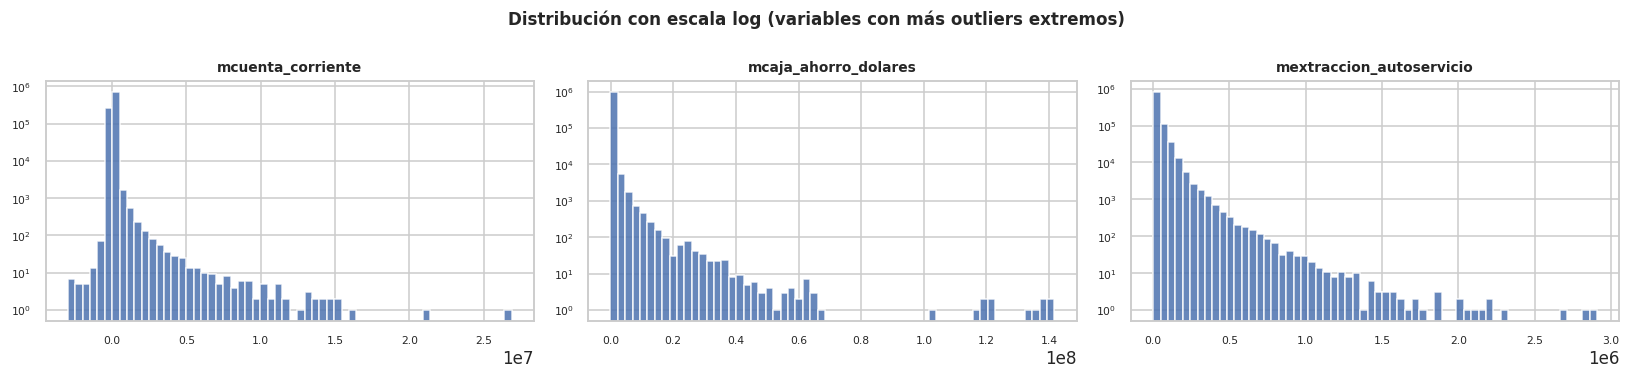

5192

In [19]:
# Para las top-3 variables con más outliers, graficamos la distribución con log scale
top_outlier_vars = outliers_df.head(3)['variable'].tolist()

if top_outlier_vars:
    fig, axes = plt.subplots(1, len(top_outlier_vars), figsize=(5 * len(top_outlier_vars), 3.5))
    if len(top_outlier_vars) == 1:
        axes = [axes]

    for ax, col in zip(axes, top_outlier_vars):
        data = df[col].dropna()
        ax.hist(data, bins=60, color='#4C72B0', edgecolor='white', alpha=0.85)
        ax.set_yscale('log')
        ax.set_title(col, fontsize=9, fontweight='bold')
        ax.tick_params(labelsize=7)

    fig.suptitle('Distribución con escala log (variables con más outliers extremos)', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

del outliers_df; gc.collect()

---
## 8 · Estabilidad del target a lo largo del tiempo

Chequeamos si hay meses donde el target esté mal etiquetado o con distribución anómala.  
Importante para la estrategia de walk-forward: no queremos entrenar sobre meses con target corrupto.

% de cada clase por mes (excluyendo mes sin target):
clase_ternaria  baja1  baja2  continua  sin_target
foto_mes                                          
202103           0.63   0.59     98.79         0.0
202104           0.59   0.70     98.71         0.0
202105           0.70   0.53     98.77         0.0
202106           0.53   0.67     98.80         0.0
202107           0.00   0.00      0.00       100.0


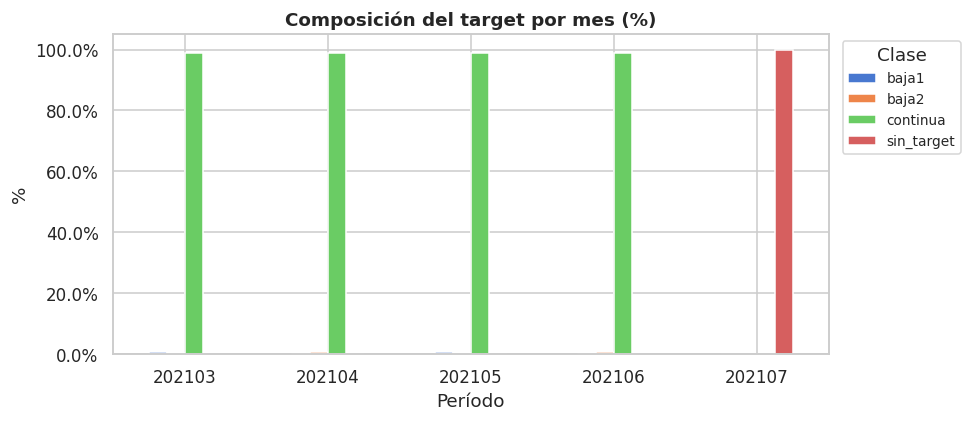

In [20]:
# Distribución del target por mes
target_por_mes = (
    df[df[COL_PERIODO] != MES_SIN_TARGET]
    .groupby([COL_PERIODO, TARGET])
    .size()
    .unstack(fill_value=0)
)

# Normalizamos
target_pct = target_por_mes.div(target_por_mes.sum(axis=1), axis=0).mul(100).round(2)
print('% de cada clase por mes (excluyendo mes sin target):')
print(target_pct)

fig, ax = plt.subplots(figsize=(9, 4))
target_pct.plot(kind='bar', ax=ax, edgecolor='white')
ax.set_title('Composición del target por mes (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Período')
ax.set_ylabel('%')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
plt.xticks(rotation=0)
plt.legend(title='Clase', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

In [21]:
# Verificamos que el mes sin target efectivamente tiene solo 'sin_target'
target_ultimo_mes = df[df[COL_PERIODO] == MES_SIN_TARGET][TARGET].value_counts(dropna=False)
print(f'\nDistribución del target en el mes {MES_SIN_TARGET} (mes a predecir):')
print(target_ultimo_mes)


Distribución del target en el mes 202108 (mes a predecir):
clase_ternaria
sin_target    164647
baja1              0
baja2              0
continua           0
Name: count, dtype: int64


---
## 9 · Resumen de hallazgos de calidad

*(Completar tras correr la notebook)*

| Dimensión | Hallazgo | Acción sugerida |
|---|---|---|
| Duplicados | — | — |
| Integridad del panel | — | — |
| Data drift | — | — |
| Missings Visa/Master | — | — |
| Consistencia cantidad-monto | — | — |
| Outliers extremos | — | — |
| Estabilidad del target | — | — |

In [22]:
# Limpieza final
del df
gc.collect()
print('✓ Análisis de calidad de datos completado.')

✓ Análisis de calidad de datos completado.
